# 01 – Cobertura amostral: postos por município e por semana

Quantos postos distintos (CNPJ) a ANP pesquisa em cada município de AL a cada
semana, e como isso muda ao longo de 2019–2026.

Base: `data/processed/precos_al.parquet` (gasolina comum + aditivada em AL).
Sem modelo. O gráfico é salvo em `docs/fig_cobertura_postos.png`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
al = pd.read_parquet(RAIZ / "data" / "processed" / "precos_al.parquet")
al["ano"] = al["data_coleta"].dt.year

MUNIS = sorted(al["municipio"].unique())            # ordem fixa (alfabética)
TODAS_SEMANAS = pd.Index(sorted(al["semana"].unique()), name="semana")

# nº de postos distintos (CNPJ) por município x semana
postos = (al.groupby(["municipio", "semana"])["cnpj"].nunique()
            .rename("n_postos").reset_index())

print(f"{len(al)} linhas | {len(TODAS_SEMANAS)} semanas "
      f"({TODAS_SEMANAS.min().date()} a {TODAS_SEMANAS.max().date()})")
print("municípios:", ", ".join(MUNIS))

30091 linhas | 387 semanas (2018-12-31 a 2026-08-24)
municípios: ARAPIRACA, DELMIRO GOUVEIA, MACEIO, PALMEIRA DOS INDIOS, RIO LARGO


## 1. Postos distintos por município e por semana — mediana, mínimo, máximo

In [2]:
resumo = (postos.groupby("municipio")["n_postos"]
          .agg(semanas_cobertas="count", minimo="min", mediana="median",
               maximo="max", media="mean")
          .round(1))
resumo["semanas_ausente"] = len(TODAS_SEMANAS) - resumo["semanas_cobertas"]
resumo = resumo[["semanas_cobertas", "semanas_ausente", "minimo", "mediana", "maximo", "media"]]

print("=" * 74)
print("POSTOS DISTINTOS (CNPJ) POR SEMANA  —  base: 387 semanas de 2019 a 2026")
print("=" * 74)
print(resumo.to_string())
print()
for m in MUNIS:
    r = resumo.loc[m]
    print(f"  {m:<20} mediana {r['mediana']:>4.0f}  (min {r['minimo']:.0f}, "
          f"max {r['maximo']:.0f})  — presente em {r['semanas_cobertas']:.0f} "
          f"de 387 semanas")

POSTOS DISTINTOS (CNPJ) POR SEMANA  —  base: 387 semanas de 2019 a 2026
                     semanas_cobertas  semanas_ausente  minimo  mediana  maximo  media
municipio                                                                             
ARAPIRACA                         371               16       2     14.0      17   13.7
DELMIRO GOUVEIA                   314               73       5      7.0      11    8.1
MACEIO                            385                2      15     19.0      25   21.3
PALMEIRA DOS INDIOS               238              149       1      8.0       8    7.4
RIO LARGO                         285              102       1      7.0       8    7.0

  ARAPIRACA            mediana   14  (min 2, max 17)  — presente em 371 de 387 semanas
  DELMIRO GOUVEIA      mediana    7  (min 5, max 11)  — presente em 314 de 387 semanas
  MACEIO               mediana   19  (min 15, max 25)  — presente em 385 de 387 semanas
  PALMEIRA DOS INDIOS  mediana    8  (min 1, max 8)  — p

## 2. Evolução 2019 → 2026

Algum município entrou ou saiu da amostra no meio do período?

In [3]:
# mediana de postos/semana por município x ano  +  nº de semanas cobertas no ano
gy = (al.groupby(["municipio", "ano", "semana"])["cnpj"].nunique()
        .rename("n").reset_index())
mediana_ano = gy.groupby(["municipio", "ano"])["n"].median().unstack("ano")
semanas_ano = gy.groupby(["municipio", "ano"])["n"].size().unstack("ano")
semanas_base = al.groupby("ano")["semana"].nunique()

print("=" * 74)
print("MEDIANA DE POSTOS/SEMANA POR ANO  (NaN = município ausente o ano todo)")
print("=" * 74)
print(mediana_ano.round(0).to_string())
print()
print("Nº DE SEMANAS COBERTAS NO ANO  (semanas na base:",
      ", ".join(f"{a}={n}" for a, n in semanas_base.items()), ")")
print("-" * 74)
print(semanas_ano.fillna(0).astype(int).to_string())

# maiores buracos por município
print()
print("=" * 74)
print("MAIORES LACUNAS CONTÍNUAS (>= 4 semanas seguidas sem nenhum posto)")
print("=" * 74)
for m in MUNIS:
    s = (postos[postos.municipio == m].set_index("semana")["n_postos"]
         .reindex(TODAS_SEMANAS))
    faltantes = pd.Series(TODAS_SEMANAS[s.isna()])
    if faltantes.empty:
        print(f"  {m:<20} sem lacunas — presente nas 387 semanas")
        continue
    grupo = faltantes.diff().dt.days.fillna(7).gt(7).cumsum()
    trechos = [(g.iloc[0], g.iloc[-1], len(g)) for _, g in faltantes.groupby(grupo) if len(g) >= 4]
    if not trechos:
        print(f"  {m:<20} só lacunas curtas (< 4 semanas)")
    for ini, fim, n in trechos:
        print(f"  {m:<20} {ini.date()} a {fim.date()}  ({n} semanas)")

MEDIANA DE POSTOS/SEMANA POR ANO  (NaN = município ausente o ano todo)
ano                  2019  2020  2021  2022  2023  2024  2025  2026
municipio                                                          
ARAPIRACA            13.0  13.0  13.0  13.0  15.0  15.0  15.0  15.0
DELMIRO GOUVEIA       7.0   7.0   7.0   7.0   9.0  10.0   9.0  10.0
MACEIO               24.0  24.0  24.0  24.0  19.0  19.0  19.0  19.0
PALMEIRA DOS INDIOS   7.0   7.0   NaN   8.0   8.0   5.0   8.0   8.0
RIO LARGO             6.0   6.0   7.0   8.0   8.0   8.0   7.0   7.0

Nº DE SEMANAS COBERTAS NO ANO  (semanas na base: 2019=53, 2020=45, 2021=52, 2022=51, 2023=52, 2024=53, 2025=53, 2026=30 )
--------------------------------------------------------------------------
ano                  2019  2020  2021  2022  2023  2024  2025  2026
municipio                                                          
ARAPIRACA              52    39    52    45    52    53    48    30
DELMIRO GOUVEIA        53    33    25    37    49  

### Leitura

- **Ninguém entra nem sai de forma permanente.** Os 5 municípios já aparecem na
  primeira semana (2018-12-31 / jan-2019) e ainda aparecem na última (ago-2026).
- **Só Maceió é amostrado de forma contínua** (385/387 semanas). Arapiraca chega
  perto (371/387).
- **O interior some por trimestres inteiros.** Palmeira dos Índios fica fora ~64
  semanas seguidas (out-2020 a jan-2022 — o ano de 2021 inteiro), e some de novo
  em 2024–2025. Rio Largo fica fora ~53 semanas em 2021. Delmiro Gouveia, ~36.
- Há uma lacuna comum a todos por volta de **out-2020** e outra em **set–out-2022**
  (parada geral da pesquisa da ANP).
- **A amostra de Maceió encolheu**: mediana de ~24 postos/semana até 2022 cai para
  ~19 de 2023 em diante.

=> Média simples por município mistura semanas cheias e semanas quase vazias, e
o interior tem buracos longos. Qualquer série do interior antes de 2023 precisa
de ressalva.

## 3. Gráfico: postos distintos por semana, uma linha por município

salvo em C:\Users\jamil\OneDrive\Área de Trabalho\Academic\curso-ciencia-dados-oxetech\projeto-gasolina-al\docs\fig_cobertura_postos.png


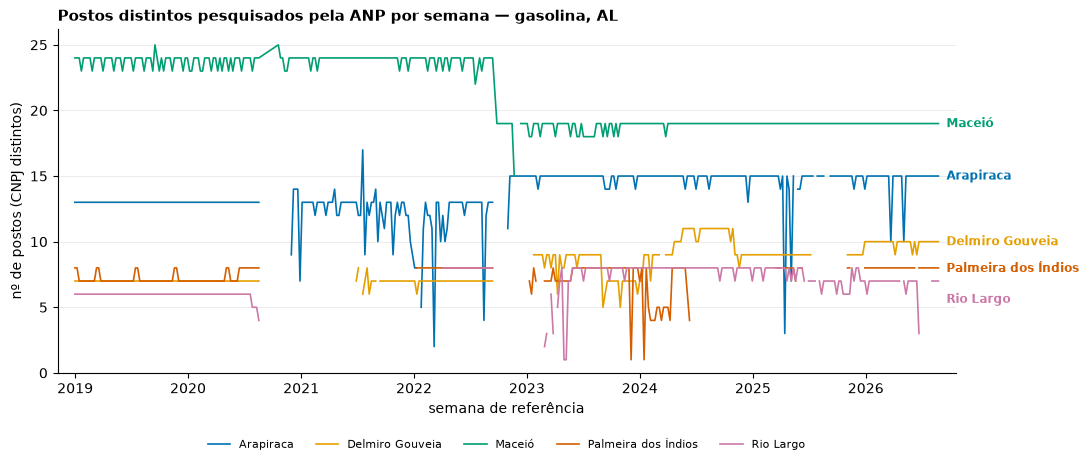

In [4]:
# paleta Okabe-Ito (segura para daltonismo), atribuída na ordem fixa de MUNIS
CORES = {
    "ARAPIRACA":            "#0072B2",
    "DELMIRO GOUVEIA":      "#E69F00",
    "MACEIO":               "#009E73",
    "PALMEIRA DOS INDIOS":  "#D55E00",
    "RIO LARGO":            "#CC79A7",
}
NOME = {
    "ARAPIRACA": "Arapiraca", "DELMIRO GOUVEIA": "Delmiro Gouveia",
    "MACEIO": "Maceió", "PALMEIRA DOS INDIOS": "Palmeira dos Índios",
    "RIO LARGO": "Rio Largo",
}

serie = (postos.pivot(index="semana", columns="municipio", values="n_postos")
         .reindex(TODAS_SEMANAS))          # semanas sem coleta viram NaN (a linha corta)

fig, ax = plt.subplots(figsize=(11, 4.8))
for m in MUNIS:
    ax.plot(serie.index, serie[m], color=CORES[m], lw=1.2, label=NOME[m])

# rótulos diretos à direita, espaçados para não colidir
fim_x = serie.index[-1]
alvos = sorted(((serie[m].dropna().iloc[-1], m) for m in MUNIS), reverse=True)
usado = []
for y, m in alvos:
    while any(abs(y - u) < 1.4 for u in usado):
        y -= 1.4
    usado.append(y)
    ax.annotate(f"  {NOME[m]}", (fim_x, serie[m].dropna().iloc[-1]),
                xytext=(fim_x, y), color=CORES[m], fontsize=8.5,
                va="center", weight="bold", annotation_clip=False)

ax.set_title("Postos distintos pesquisados pela ANP por semana — gasolina, AL",
             fontsize=11, weight="bold", loc="left")
ax.set_ylabel("nº de postos (CNPJ distintos)")
ax.set_xlabel("semana de referência")
ax.set_ylim(0, None)
ax.margins(x=0.02)
ax.grid(axis="y", lw=0.5, alpha=0.35)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center",
          bbox_to_anchor=(0.5, -0.16))
fig.tight_layout()

destino = RAIZ / "docs" / "fig_cobertura_postos.png"
destino.parent.mkdir(exist_ok=True)
fig.savefig(destino, dpi=150, bbox_inches="tight")
print("salvo em", destino)
plt.show()